In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'marenaria')
pth_res = os.path.join(pth_data, 'results')
pth_clf = os.path.join(pth_res, 'classifier')
pth_out = os.path.join(pth_res, 'marenaria')
pth_fig = os.path.join(pth, 'figures', 'marenaria')

In [3]:
fn = os.path.join(pth_clf, 'logreg.csv')
beta = pd.read_csv(fn, index_col = 0)
beta

,beta
GSE162534,0.562046
GSE229103,4.880419
rRNAModifications,3.368317
intercept_,1.128921


In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata

AnnData object with n_obs × n_vars = 6 × 43038
    obs: 'sample', 'GSE162534', 'GSE229103', 'rRNAModifications'
    uns: 'log1p', 'sample_colors'
    layers: 'counts', 'score'

In [5]:
# predict branches (logreg)
sig = lambda x: 100 / (1 + np.exp(-x))
X = adata.obs[beta.index[:-1]]
X['intercept_'] = 1.
prob = X.dot(beta).apply(sig)
adata.obs['Branch2'] = prob
adata.obs['Branch1'] = 100 - prob

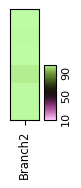

In [23]:
# probabilities heatmap
hm = sc.pl.heatmap(adata, 'Branch2', 'sample',
                   cmap = 'vanimo', vcenter = 50,
                   figsize = (.75, 1.5),
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_cb = ax_hm.figure.axes[1]
ax_grp.set_visible(False)

pos_hm  = ax_hm.get_position()
pos_cb = ax_cb.get_position()

ax_hm.invert_yaxis()
for l in ax_hm.collections:
    l.remove()

ax_cb.set_position([pos_cb.x0, pos_cb.y0,
                    1.125 * pos_cb.width,
                    .5 * pos_cb.height])
ticks = [10, 50, 90]
ax_cb.set_yticks(ticks, ticks, size = 8, rotation = 90)
ax_cb.tick_params(length = 0)

fn = os.path.join(pth_fig, 'probabilities.pdf')
plt.savefig(fn, bbox_inches = 'tight', dpi = 1200)

In [15]:
# save results
df = adata.obs[['Branch1', 'Branch2']].T
df.to_csv(os.path.join(pth_out, 'probabilities.csv'))

In [16]:
adata.write(os.path.join(pth_in, 'probabilities.h5ad'))